# DATA 443 Final Group Project
## Contributors: Muntaha Al-Taie

# Introduction
Environmental monitoring and lake management rely heavily on understanding the causes of poor water quality; in particular, heavy metals (e.g., mercury, methyl mercury, lead, vanadium) can be harmful to aquatic ecosystems if their respective levels exceed recommended limits or regulatory standards. Routine monitoring of water quality at Kearl Lake has yielded several sets of pollution-related metal concentrations; however, the data collected for each of these different pollutant metals were not sampled at the same time, making it difficult to directly compare the relationships between metals and other water quality characteristics to build a predictive relationship.

Given this issue, we have decided to focus more on a data-supported or feasible question, rather than attempting to infer the prediction of other water quality measurements (e.g., nutrients, pH, or oxygen saturation) based on the concentrations of heavy metals; we are trying to ascertain if the concentrations of heavy metals can be predicted based on water quality measurements available within the dataset and the sampling conditions surrounding each sample collection.

Our dataset is made up of parameters such as depth of the water, pH of the water, dissolved oxygen saturation levels, levels of nutrients, and concentrations of specific heavy metals and their contamination levels. We will use these variables as inputs to develop machine learning models that will determine if concentrations of heavy metals at certain times can be accurately predicted.

# Objective 
The aim of this project is to test if water quality measures and associated sampling conditions can be utilized as predictors of metal violations in Kearl Lake, and to address the following objectives:

1. To prepare the raw Kearl Lake data for analysis by cleaning the numeric variables to ensure standard formatting throughout the entire dataset and generating useable values for the exceedances based on water quality standards.

2. To create and compare two types of machine learning models (Logistic Regression and Random Forest) to determine the likelihood of a single metal exceeding an allowable level and the likelihood of some combination of all metals exceeding an allowable level; as well as evaluate the overall performance of the models based on the accuracy, precision, recall, F1 score and ROC AUC; and determine what features of the Kearl Lake water quality dataset contribute most significantly to the models' predictive capabilities.

3. To provide an evidence-based analysis and argument as to whether these standard water quality measures provide any meaningful support to predict the potential risks of metals in Kearl Lake.

# Dataset Description

# Research Question

*To what extent can water-quality measurements and sampling conditions predict metal exceedances at Kearl Lake?*  

This research question identifies a clearly defined outcome -- metal exceedances at Kearl Lake -- and a bounded set of predictores, namely water-quality measurements and sampling conditions. These variables are quantifiable and directly relevant to the monitoring context, ensuring that the scope of this study remains practical.  

By focusing on the extent to which exceedances can be predicted, the study moves beyond descriptive monitoring to a measurable assessment of predictive strength. This framing allows for the application of machine learning methods, including Linear Regression, Random Forest, and feature importance analysis, to evaluate relationships between predictor variables and exceedance occurence. The use of performance metrics will further ensure that predictive capacities can be quantified and validated.  

Moreover, since the dataset is localized to Kearl Lake, the analysis remains context-specific, enabling results to be interpreted within the environmental and regulatory framework of the study area.


# Data Cleaning and Preprocessing
### 1. Import libraries and load the raw CSV and Fix the header row and clean column names

In this step we import the libraries we need and read the raw Kearl Lake CSV file.  
The file contains metadata rows at the top, so we load it without a header first.
Row 1 of the file contains the real column names.  
We drop the top metadata rows, apply this row as the header, and strip whitespace from column labels.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load raw CSV and fix header 
path = "KEARL.csv"

# File has metadata rows -> read with no header
df_raw = pd.read_csv(path, header=None)

# Row 1 is the real header
header = df_raw.iloc[1]

# Drop the first two metadata rows -> apply header
df = df_raw.iloc[2:].copy()
df.columns = header

# Clean column names by stripping whitespace, ensure string type
df.columns = df.columns.astype(str).str.strip()

### 2. Parse timestamps and define numeric columns

Here we convert the sampling timestamp (if present) to a proper datetime,  
and define the list of columns that should be treated as numeric water-quality or metal measurements.

In [16]:
# Parsing/numeric cleaning 

# Parse timestamp 
if "Sampling Timestamp" in df.columns:
    df["Sampling Timestamp"] = pd.to_datetime(df["Sampling Timestamp"], errors="coerce")

# Numeric columns
numeric_cols = [
    "Mercury Total",
    "Mercury Dissolved",
    "Methyl Mercury",
    "Lead Total Recoverable",
    "Lead Dissolved",
    "Vanadium Dissolved",
    "Vanadium Total Recoverable",
    "Water depth",
    "Phosphorus Total",
    "Nitrogen Total",
    "pH",
    "Oxygen dissolved % saturation",
]

### 3. Clean detection-limit symbols and convert to numeric

The numeric columns sometimes contain `<` signs (below detection limit),  
commas, or extra whitespace. We remove these artefacts and coerce all values to numeric.  
Non-convertible entries become NaN.

In [17]:
# Clean and convert numeric columns
for col in numeric_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace("<", "", regex=False) # Remove detection limit sign
            .str.replace(",", "", regex=False) # Remove commas
            .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

### 4. Drop rows with no numeric information and inspect the result

If a row has all numeric variables missing, it is not useful for modelling.  
We drop such rows and then print a small preview and `info()` summary  
to confirm that the cleaning worked.

In [18]:
# Drop rows where all numeric vars are NaN 
existing_numeric = [c for c in numeric_cols if c in df.columns]
df = df.dropna(subset=existing_numeric, how="all")

print("After basic cleaning:")
print(df[existing_numeric].head())
print(df.info())

After basic cleaning:
1  Mercury Total  Mercury Dissolved  Methyl Mercury  Lead Total Recoverable  \
2           0.05                NaN             NaN                     NaN   
3           0.05                NaN             NaN                     NaN   
4           0.05                NaN             NaN                     NaN   
5           0.05                NaN             NaN                     NaN   
6           0.05                NaN             NaN                     NaN   

1  Lead Dissolved  Vanadium Dissolved  Vanadium Total Recoverable  \
2             NaN                 NaN                         NaN   
3             NaN                 NaN                         NaN   
4             NaN                 NaN                         NaN   
5             NaN                 NaN                         NaN   
6             NaN                 NaN                         NaN   

1  Water depth  Phosphorus Total  Nitrogen Total  pH  \
2          NaN               NaN

### 5. Define guideline thresholds for each metal

We now define the regulatory guideline values (in µg/L) for each metal.  
These thresholds will be used to create binary exceedance flags.

In [19]:
# CCME/guideline thresholds (ug/L)
HG_TOTAL_GUIDE = 0.026 # CCME total Hg
MEHG_GUIDE     = 0.004 # CCME MeHg
PB_TOTAL_GUIDE = 7.0   # AB Env Pb (assumed hardness 50 mg/L)
V_TOTAL_GUIDE  = 100.0 # AB Env interim V guideline

### 6. Create exceedance flags for each individual metal

For each metal, we compare the measured concentration to its guideline.  
If the value is above the guideline, the corresponding `_exceed` flag is set to 1, else 0.  
If a metal column is missing, we default its exceedance flag to 0.

In [20]:
# Exceedance flags (1 = exceeds guideline, 0 = compliant) 

# Create each exceedance flag 
if "Mercury Total" in df.columns:
    df["Hg_exceed"] = (df["Mercury Total"] > HG_TOTAL_GUIDE).astype(int)
else:
    df["Hg_exceed"] = 0

if "Methyl Mercury" in df.columns:
    df["MeHg_exceed"] = (df["Methyl Mercury"] > MEHG_GUIDE).astype(int)
else:
    df["MeHg_exceed"] = 0

if "Lead Total Recoverable" in df.columns:
    df["Pb_exceed"] = (df["Lead Total Recoverable"] > PB_TOTAL_GUIDE).astype(int)
else:
    df["Pb_exceed"] = 0

if "Vanadium Total Recoverable" in df.columns:
    df["V_exceed"] = (df["Vanadium Total Recoverable"] > V_TOTAL_GUIDE).astype(int)
else:
    df["V_exceed"] = 0

### 7. Create a combined “Any_exceed” label and check class balance

Finally, we create a combined flag that is 1 if **any** of the four metals exceeds its guideline in a given sample.  
We then print the value counts for all exceedance flags to see how common exceedances are.

In [21]:
# Combined “any exceedance” label 
df["Any_exceed"] = (
    (df["Hg_exceed"] == 1) |
    (df["MeHg_exceed"] == 1) |
    (df["Pb_exceed"] == 1) |
    (df["V_exceed"] == 1)
).astype(int)

# Sanity check 
print("\nExceedance counts:")
print("Hg_exceed:\n",   df["Hg_exceed"].value_counts())
print("\nMeHg_exceed:\n", df["MeHg_exceed"].value_counts())
print("\nPb_exceed:\n",   df["Pb_exceed"].value_counts())
print("\nV_exceed:\n",    df["V_exceed"].value_counts())
print("\nAny_exceed:\n",  df["Any_exceed"].value_counts())


Exceedance counts:
Hg_exceed:
 Hg_exceed
0    315
1     35
Name: count, dtype: int64

MeHg_exceed:
 MeHg_exceed
0    340
1     10
Name: count, dtype: int64

Pb_exceed:
 Pb_exceed
0    350
Name: count, dtype: int64

V_exceed:
 V_exceed
0    350
Name: count, dtype: int64

Any_exceed:
 Any_exceed
0    305
1     45
Name: count, dtype: int64


# Machine Learning Modelling:

### Modelling helper function: `run_models_for_target`

To begin, we will start by creating a **single reusable function** that runs our full modelling pipeline for any
and all exceedance targets (e.g., `Hg_exceed`, `Pb_exceed`, `Any_exceed`).

This function follows this sequence:

1. **Imports the required libraries** (scikit-learn, NumPy, matplotlib).
2. **Chooses the feature columns**:
   - starts with only numeric columns  
   - removes exceedance label columns (`Hg_exceed`, `MeHg_exceed`, `Pb_exceed`, `V_exceed`, `Any_exceed`)  
   - removes any columns we explicitly choose to drop.
3. **Handles missing values** by imputing the median for all the feature columns.
4. **Checks class balance** for the given target (how many 0s vs 1s) and skips modelling in the case that there is only one class.
5. **Splits the data into train and test sets**:
   - uses a stratified split whenever possible  
   - if stratification fails, it will go back to a manual per-class split to ensure both classes appear in train and test.
6. **Fits two models**:
   - Logistic Regression (linear baseline, with `class_weight="balanced"`)  
   - Random Forest Classifier (non-linear tree-based model).
7. **Evaluates both models** using:
   - Performance metrics: Accuracy, Precision, Recall, F1-score  
   - ROC-AUC (when defined)  
   - `classification_report` (per-class metrics)  
   - confusion matrix for the Random Forest.
8. **Plots Random Forest feature importances** to show which predictors have the largest influence on the target.
9. **Returns** the fitted models and the train/test splits in a dictionary so we can reuse them later.


In [22]:
def run_models_for_target(df, target_col, drop_feature_cols=None, test_size=0.2, random_state=42):
    """
    df: cleaned dataframe with exceedance columns already created (from the cleaning block)
    target_col: name of the exceedance column to model (e.g., 'V_exceed', 'Hg_exceed', 'Any_exceed')
    drop_feature_cols: list of columns to drop from X (IDs, timestamps, that metal's conc, etc.)
    """

    import pandas as pd
    import numpy as np
    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import (
        accuracy_score, precision_score, recall_score,
        f1_score, roc_auc_score, confusion_matrix,
        classification_report
    )
    import matplotlib.pyplot as plt

    if drop_feature_cols is None:
        drop_feature_cols = []

    # 1. Select numeric columns as candidates for features
    numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns.tolist()

    # Columns we do NOT want to use as predictors (targets / other labels)
    label_cols = ["Hg_exceed", "MeHg_exceed", "Pb_exceed", "V_exceed", "Any_exceed"]

    # Build final feature list:
    feature_cols = [
        col for col in numeric_cols
        if col not in label_cols and col not in drop_feature_cols
    ]

    print(f"\n=== Modeling target: {target_col} ===")
    print("Using feature columns:", feature_cols)

    # 2. Copy df and IMPUTE missing values instead of dropping rows
    df_model = df.copy()
    df_model[feature_cols] = df_model[feature_cols].fillna(df_model[feature_cols].median())

    X = df_model[feature_cols]
    y = df_model[target_col].astype(int)

    # Sanity check to make sure we actually have both classes
    print("\nClass balance for", target_col)
    print(y.value_counts())
    print(f"Total usable rows: {len(df_model)}")

    if y.nunique() < 2:
        print(f"Cannot model {target_col}: only one class present in the data.")
        return None

    # 3. Train/test split 
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=random_state,
            stratify=y      # force both classes in train & test
        )
    except ValueError as e:
        print("Stratified split failed:", e)
        print("Falling back to manual per-class split to keep both classes.\n")

        # Manual fallback to guarantee both classes in train & test
        X_pos = X[y == 1]
        X_neg = X[y == 0]
        y_pos = y[y == 1]
        y_neg = y[y == 0]

        X_train_pos, X_test_pos, y_train_pos, y_test_pos = train_test_split(
            X_pos, y_pos, test_size=test_size, random_state=random_state
        )
        X_train_neg, X_test_neg, y_train_neg, y_test_neg = train_test_split(
            X_neg, y_neg, test_size=test_size, random_state=random_state
        )

        X_train = pd.concat([X_train_pos, X_train_neg], axis=0)
        X_test  = pd.concat([X_test_pos,  X_test_neg],  axis=0)
        y_train = pd.concat([y_train_pos, y_train_neg], axis=0)
        y_test  = pd.concat([y_test_pos,  y_test_neg],  axis=0)

    # Double-check that train actually has both classes
    if y_train.nunique() < 2:
        print("After splitting, y_train still has only one class. "
              "Models cannot be trained meaningfully.")
        print("y_train value counts:")
        print(y_train.value_counts())
        return None

    # 4. Logistic Regression (baseline classification model)
    log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
    log_reg.fit(X_train, y_train)
    y_pred_lr = log_reg.predict(X_test)
    y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

    print("\n--- Logistic Regression Results ---")
    print("Accuracy:",  round(accuracy_score(y_test, y_pred_lr), 3))
    print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 3))
    print("Recall:",    round(recall_score(y_test, y_pred_lr, zero_division=0), 3))
    print("F1-score:",  round(f1_score(y_test, y_pred_lr, zero_division=0), 3))
    try:
        print("ROC-AUC:",  round(roc_auc_score(y_test, y_prob_lr), 3))
    except ValueError:
        print("ROC-AUC: not defined (only one class in test set)")

    print("\nClassification report (Logistic Regression):")
    print(classification_report(y_test, y_pred_lr, zero_division=0))

    # 5. Random Forest Classifier 
    rf = RandomForestClassifier(
        n_estimators=300,
        random_state=random_state,
        class_weight="balanced",
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    y_prob_rf = rf.predict_proba(X_test)[:, 1]

    print("\n--- Random Forest Results ---")
    print("Accuracy:",  round(accuracy_score(y_test, y_pred_rf), 3))
    print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 3))
    print("Recall:",    round(recall_score(y_test, y_pred_rf, zero_division=0), 3))
    print("F1-score:",  round(f1_score(y_test, y_pred_lr, zero_division=0), 3))
    try:
        print("ROC-AUC:",  round(roc_auc_score(y_test, y_prob_rf), 3))
    except ValueError:
        print("ROC-AUC: not defined (only one class in test set)")

    print("\nClassification report (Random Forest):")
    print(classification_report(y_test, y_pred_rf, zero_division=0))

    # Confusion matrix for RF
    cm = confusion_matrix(y_test, y_pred_rf)
    print("Confusion matrix (Random Forest):")
    print(cm)

    # 6. Feature importance plot
    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1]

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(feature_cols)), importances[indices])
    plt.xticks(range(len(feature_cols)), [feature_cols[i] for i in indices], rotation=90)
    plt.title(f"Feature Importances for {target_col} (Random Forest)")
    plt.tight_layout()
    plt.show()

    return {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "log_reg": log_reg,
        "rf": rf
    }

### Run models for each exceedance target

We now run each exceedance type we created during our cleaning through our `run_models_for_target()` function for a total of five times.

For each target, we also remove that specific metal’s concentration column from the list of features to prevent any **data leakage** from occuring (so that the model does not use a metal's own values to predict its exceedance).

The five targets are:

- `V_exceed` — Vanadium exceedances  
- `Hg_exceed` — Mercury exceedances  
- `Pb_exceed` — Lead exceedances  
- `MeHg_exceed` — Methyl Mercury exceedances  
- `Any_exceed` — at least one metal exceedance  

Each call trains:
- a Logistic Regression baseline model  
- a Random Forest classifier

and finishes by printing all the key performance metrics and plotting feature importances.


=== Modeling target: V_exceed ===
Using feature columns: ['Mercury Total', 'Mercury Dissolved', 'Methyl Mercury', 'Lead Total Recoverable', 'Lead Dissolved', 'Vanadium Dissolved', 'Water depth', 'Phosphorus Total', 'pH', 'Oxygen dissolved % saturation', 'Nitrogen Total']

Class balance for V_exceed
V_exceed
0    350
Name: count, dtype: int64
Total usable rows: 350
Cannot model V_exceed: only one class present in the data.

=== Modeling target: Hg_exceed ===
Using feature columns: ['Mercury Dissolved', 'Methyl Mercury', 'Lead Total Recoverable', 'Lead Dissolved', 'Vanadium Dissolved', 'Vanadium Total Recoverable', 'Water depth', 'Phosphorus Total', 'pH', 'Oxygen dissolved % saturation', 'Nitrogen Total']

Class balance for Hg_exceed
Hg_exceed
0    315
1     35
Name: count, dtype: int64
Total usable rows: 350

--- Logistic Regression Results ---
Accuracy: 0.243
Precision: 0.117
Recall: 1.0
F1-score: 0.209
ROC-AUC: 0.405

Classification report (Logistic Regression):
              precisi

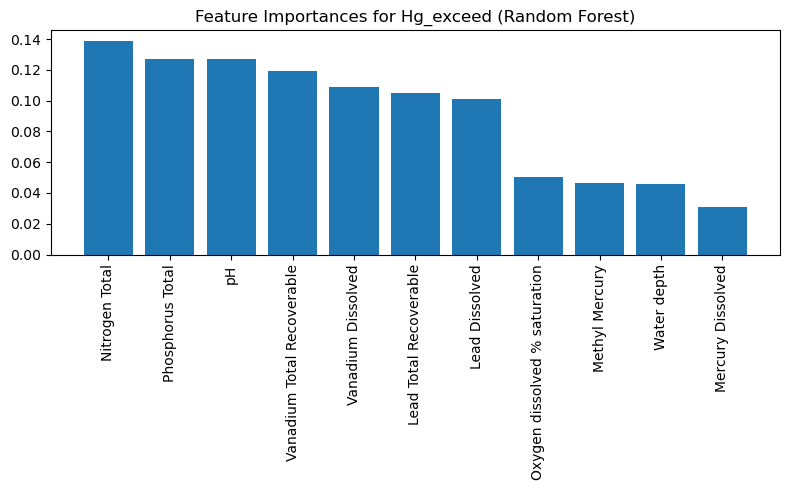


=== Modeling target: Pb_exceed ===
Using feature columns: ['Mercury Total', 'Mercury Dissolved', 'Methyl Mercury', 'Vanadium Dissolved', 'Vanadium Total Recoverable', 'Water depth', 'Phosphorus Total', 'pH', 'Oxygen dissolved % saturation', 'Nitrogen Total']

Class balance for Pb_exceed
Pb_exceed
0    350
Name: count, dtype: int64
Total usable rows: 350
Cannot model Pb_exceed: only one class present in the data.

=== Modeling target: MeHg_exceed ===
Using feature columns: ['Mercury Total', 'Mercury Dissolved', 'Lead Total Recoverable', 'Lead Dissolved', 'Vanadium Dissolved', 'Vanadium Total Recoverable', 'Water depth', 'Phosphorus Total', 'pH', 'Oxygen dissolved % saturation', 'Nitrogen Total']

Class balance for MeHg_exceed
MeHg_exceed
0    340
1     10
Name: count, dtype: int64
Total usable rows: 350

--- Logistic Regression Results ---
Accuracy: 0.314
Precision: 0.04
Recall: 1.0
F1-score: 0.077
ROC-AUC: 0.426

Classification report (Logistic Regression):
              precision    

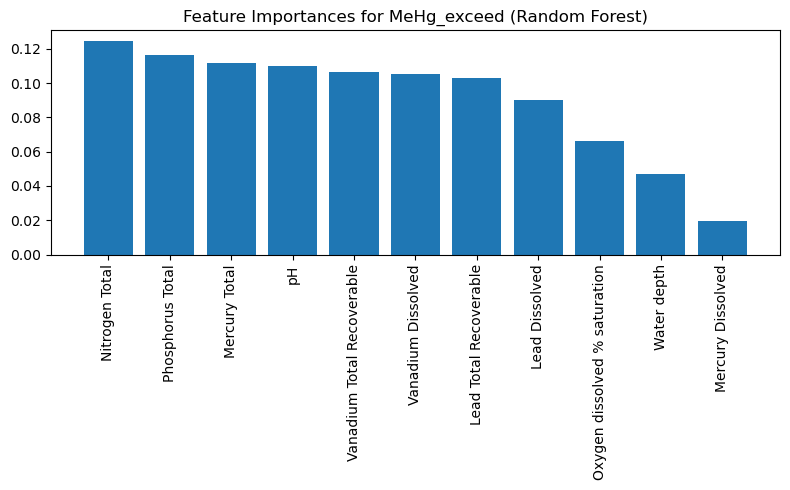


=== Modeling target: Any_exceed ===
Using feature columns: ['Mercury Dissolved', 'Lead Dissolved', 'Vanadium Dissolved', 'Water depth', 'Phosphorus Total', 'pH', 'Oxygen dissolved % saturation', 'Nitrogen Total']

Class balance for Any_exceed
Any_exceed
0    305
1     45
Name: count, dtype: int64
Total usable rows: 350

--- Logistic Regression Results ---
Accuracy: 0.271
Precision: 0.15
Recall: 1.0
F1-score: 0.261
ROC-AUC: 0.412

Classification report (Logistic Regression):
              precision    recall  f1-score   support

           0       1.00      0.16      0.28        61
           1       0.15      1.00      0.26         9

    accuracy                           0.27        70
   macro avg       0.57      0.58      0.27        70
weighted avg       0.89      0.27      0.28        70


--- Random Forest Results ---
Accuracy: 0.829
Precision: 0.429
Recall: 1.0
F1-score: 0.261
ROC-AUC: 0.902

Classification report (Random Forest):
              precision    recall  f1-score   

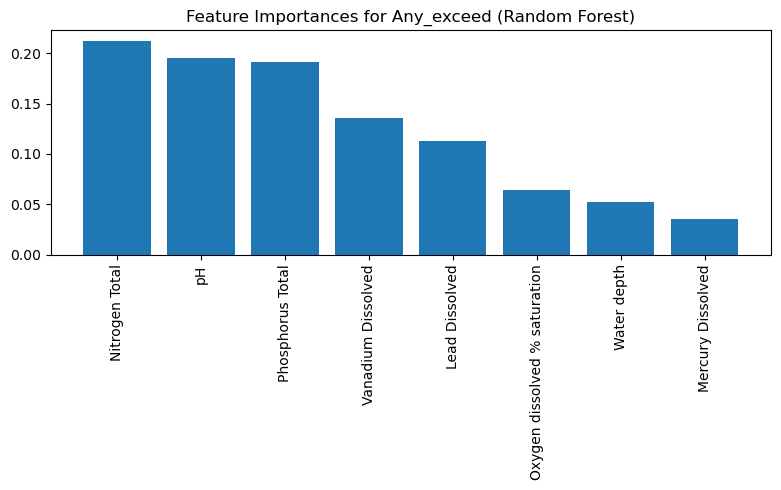

In [23]:
# Vanadium exceedances (don’t use Vanadium concentration itself as a predictor)
results_v = run_models_for_target(
    df,
    target_col="V_exceed",
    drop_feature_cols=["Vanadium Total Recoverable"]
)

# Mercury exceedances
results_hg = run_models_for_target(
    df,
    target_col="Hg_exceed",
    drop_feature_cols=["Mercury Total"]
)

# Lead exceedances
results_pb = run_models_for_target(
    df,
    target_col="Pb_exceed",
    drop_feature_cols=["Lead Total Recoverable", "Lead Dissolved"]
)

# Methyl Mercury exceedances
results_mehg = run_models_for_target(
    df,
    target_col="MeHg_exceed",
    drop_feature_cols=["Methyl Mercury"]
)

# Any metal exceedance
results_any = run_models_for_target(
    df,
    target_col="Any_exceed",
    drop_feature_cols=["Mercury Total", "Vanadium Total Recoverable", "Lead Total Recoverable", "Methyl Mercury"]
)

# Model Evaluation and Interpretation:

### Model evaluation: ROC curves and AUC

We utilize a helper function `plot_roc_from_results` which will allow us to compare the performance of our logistic regression and random forest models
for each exceedance.

This function:

1. Takes the `results` dictionary returned by `run_models_for_target()`.
2. Uses each model's predicted **probabilities** of exceedance.
3. Computes the **ROC curve**.
4. Calculates the **Area Under the Curve (AUC)** for Logistic Regression and Random Forest.
5. Plots both ROC curves on the same figure, along with a diagonal “random classifier” baseline.


In [29]:
from sklearn.metrics import roc_curve, auc

# using results from models
def plot_roc_from_results(results, target_col):

    # extract objects from results
    y_test = results["y_test"]
    log_reg = results["log_reg"]
    rf = results["rf"]

    # using predicted probabilities, indexing second column (probability of exceedance)
    y_prob_lr = log_reg.predict_proba(results["X_test"])[:, 1]
    y_prob_rf = rf.predict_proba(results["X_test"])[:, 1]

    # ROC curve for each model
    fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

    # AUC
    auc_lr = auc(fpr_lr, tpr_lr)
    auc_rf = auc(fpr_rf, tpr_rf)

    # plot curves
    plt.figure(figsize=(7,7))
    plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
    plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
    plt.plot([0,1],[0,1], "k--", label="Random Classifier")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Recall)")
    plt.title(f"ROC Curves for {target_col}")
    plt.legend()
    plt.show()


### Plot ROC curves for each exceedance target

With our new `plot_roc_from_results` function, we now generate ROC curves for each of the exceedance targets with valid models.

We plot the ROC curves for:
- **Hg_exceed** — Mercury exceedances  
- **MeHg_exceed** — Methyl Mercury exceedances  
- **Any_exceed** — at least one metal exceedance  

These plots compare Logistic Regression vs Random Forest using their AUC values,
helping us understand which model provides better discrimination between exceedance and non-exceedance cases.

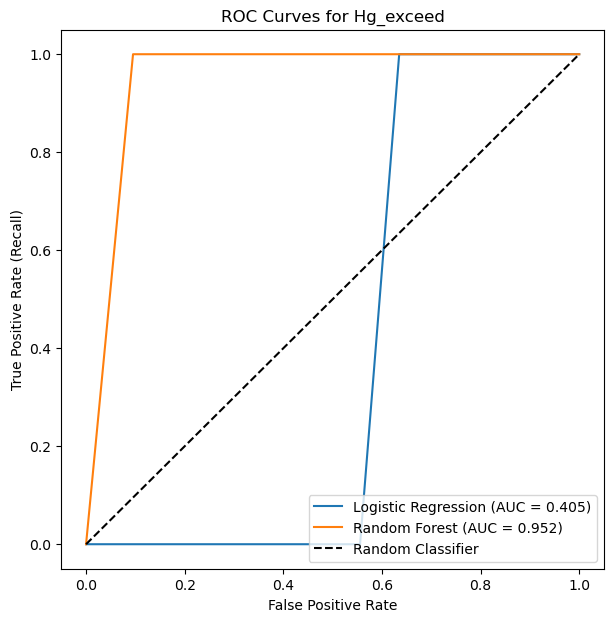

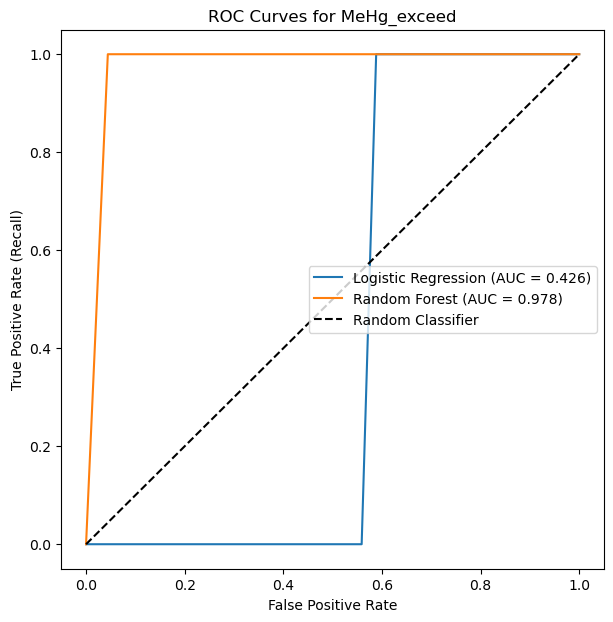

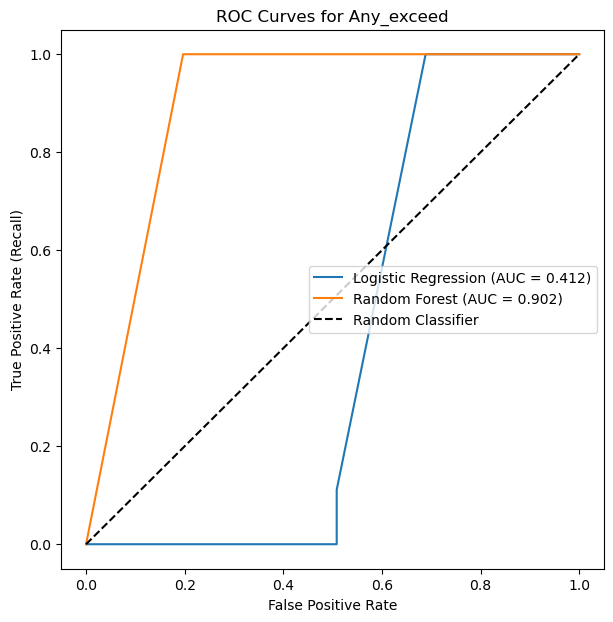

In [30]:
plot_roc_from_results(results_hg, "Hg_exceed")

plot_roc_from_results(results_mehg, "MeHg_exceed")

plot_roc_from_results(results_any, "Any_exceed")

The ROC curves presented above appear to lack the characteristic smooth curvature that typically accompanies this type of plot. This pattern is most likely a consequence of the pronounced class imbalance in the dataset, as highlighted in the modeling results in the previous section. When one class (in this case, exceedances) is much rarer than the other, the models tend to produce probability scores clusteres at extreme values (close to 0 or 1). As a result, the ROC curve produce straight segments rather than a gradual curve, offering limited insight into threshold-dependent trade-offs and underscoring the challenges of evaluating predictive performance under imbalance.

## Result Comparison

From the previous section, we obtained the following metrics for the metals that we were able to model: accuracy, precision, recall, ROC-AUC.


Mercury (Hg)

|                     | Accuracy | Precision | Recall |  F1 | ROC-AUC | 
|---------------------|----------|-----------|--------|-----|---------|
| Logistic Regression | 0.243    | 0.117     | 1.0    |0.209| 0.405   |
| Random Forest       | 0.914    | 0.538     | 1.0    |0.209| 0.952   |


Methyl Mercury (MeHg)

|                     | Accuracy | Precision | Recall |  F1 | ROC-AUC | 
|---------------------|----------|-----------|--------|-----|---------|
| Logistic Regression | 0.314    | 0.04      | 1.0    |0.077|0.426    |
| Random Forest       | 0.957    | 0.4       | 1.0    |0.077|0.978    |

Any Metals

|                     | Accuracy | Precision | Recall |  F1 | ROC-AUC | 
|---------------------|----------|-----------|--------|-----|---------|
| Logistic Regression | 0.271    | 0.15      | 1.0    |0.261|0.412    |
| Random Forest       | 0.829    | 0.429     | 1.0    |0.261|0.902    |  


Across all target metals, recall = $ TP/(TP + FN) $ was consistently perfect (1.0), meaning both Logistic Regression and Random Forest correctly identified every exceedance event without false negatives. This indicates that the models are highly sensitive. However, they also flagged many non-exceedances as exceedances, producing false positives. This outcome is likely linked to the strong class imbalance in the dataset and the absence of training records for metals that never exceed guideline limits.

Our findings also point to poor performance using Logistic Regression: its accuracy was very low (0.243 - 0.314) and its precision was near zero, meaning almost all predicted exceedances are false alarms. Its ROC-AUC scores hover around the midrange (i.e. 0.405-0.426), essentially suggesting random performance. Furthermore, its F1-scores were poor, reflecting the imbalance between recall and precision. Overall, Logistic Regression is not separating exceedances from non-exceedances in a meaningful way.  

Random Forest, by contrast, achieved substantially higher accuracy (0.829 - 0.957), stronger precision (0.4 - 0.538), and excellent ROC-AUC valus (0.902 - 0.978). Although its recall and F1-scores matched those of Logistic Regression, its superior accuracy and discriminative ability make Random Forest the stronger model for these targets and, therefore, the research question.


# Conclusion:

Taken together, these results show that the water-quality measurements and sampling conditions at Kearl Lake can reliably predict metal exceedance, but only when modeled with fleible, non-linear approaches such as Random Forest. Logistic Regression's poor performance underscores the complexity of these relationships and the need for models that are capable of capturing non-linear patterns. Importantly, all models achieved perfect recall, ensuing that exceedances were never missed, though moderate precision indicates some false alarms.

Overall, the findings suggest that predictive modeling can serve as an early-warning tool for environmental monitoring, while emphasizing the trade-off between safety (high recall) and efficiency (precision).

## Future Steps  

#### Limitations and Potential Improvements

A key limitation of this project is the strong class imbalance present in the dataset. Many metals rarely exceed their guideline limits, which means the majority of records are non-exceedances. This imbalance skews the training process and leads to models that are highly sensitive but prone to false alarms, as we saw in our analysis. This outcome reflects the difficulty of learning meaningful patterns when the positive case is underrepresented. It also reduced the interpretive value of the ROC curves, which rely on variation in predicted probabilities across thresholds. In cases where exceedances are extremely rare or absent, predictive modeling becomes impossible, as there is no positive class to train on. These limitations highlight the challenges of applying machine learning to environmental monitoring when exceedance occurrences are infrequent.

Future work could explore methods specifically designed to handle class imbalance -- perhaps resampling techniques. It may also be interesting to experiment with threshold tuning to see if it achieves better balances between sensitivity and specificity.

# References: